# Fine-tuning the shipped MACE model

Test of the new training loop (`train.py`) on the shipped model (`model/example_weights_v2`, converted from
`20240604_160152`: integrated scheme, z = 8, `nb_evol` = 16, `abs_idn`).

1. Load the converted weights into the new `MACE` class.
2. Build the train/validation loaders exactly as the original run did (`CSEdata`, seed 0).
3. Baseline losses of the shipped weights.
4. Train a few more epochs with `train()`. The targets are now `n[j+i+1]`, so the old off-by-one is gone.
5. Compare the original and the fine-tuned model on the held-out `data/test/mid_dens` model.

Run from the repo root.

In [2]:
import copy, json
from pathlib import Path
from time    import strftime

import numpy             as np
import torch
import matplotlib.pyplot as plt

assert Path('src/mace').is_dir(), 'Run this notebook from the MACE repo root.'

import src.mace.CSE_0D.dataset as ds
import src.mace.loss           as L
from   src.mace.mace           import MACE
from   src.mace.train                   import train, run_epoch, make_windows

## Settings

In [3]:
WEIGHTS   = Path('model/example_weights_v2')
SNAPSHOT  = 7          ## nn/nn7.pt, the snapshot load&test.ipynb uses (there is no final nn.pt)
NB_EPOCHS = 5
LR        = 1e-5       ## the original run used 1e-4; smaller for fine-tuning
SAVE      = False      ## True: write weights + losses to model/<timestamp>_finetune/

meta     = json.load(open(WEIGHTS / 'meta.json'))
NB_EVOL  = meta['nb_evol']      ## 16
LOSSTYPE = meta['losstype']     ## 'abs_idn'
print(f"nb_evol = {NB_EVOL}, losstype = {LOSSTYPE}, atol = {meta['atol']}, rtol = {meta['rtol']}")

nb_evol = 16, losstype = abs_idn, atol = 1e-05, rtol = 0.01


## 1. Model

The tolerances have to be passed explicitly: the shipped model was trained with `rtol = 1e-2`.
`original` is a frozen copy for the comparison at the end.

In [4]:
model = MACE(n_dim=468, p_dim=4, z_dim=meta['z_dim'], ae_type=meta['ae_type'],
             atol=meta['atol'], rtol=meta['rtol'])
model.load_state_dict(torch.load(WEIGHTS / 'nn' / f'nn{SNAPSHOT}.pt'))
original = copy.deepcopy(model).eval()

print(f'{sum(q.numel() for q in model.parameters())} trainable parameters')

284692 trainable parameters


## 2. Data

Same call as `routine.py`, but with `num_workers = 0` (worker processes do not work from a notebook on Windows).
Every item is one complete 1D model; `batch_size` must be 1 because the models have different lengths.

Note: `CSEdata` draws the models **with replacement**, so the training and validation sets can share models.
The validation loss is then partly measured on training data.

In [5]:
traindata, validdata, train_loader, valid_loader = ds.get_data(
    '1DCSE', nb_samples=meta['nb_samples'], dt_fract=meta['dt_fract'], nb_test=meta['nb_test'],
    inpackage=True, batch_size=1, kwargs={'num_workers': 0})

print('train:', [Path(p).parts[0][:40] for p in traindata.path])
print('valid:', [Path(p).parts[0][:40] for p in validdata.path])

> Train state: True
Found paths: 13
[12  5  0  3 11  3  7  9  3  5]
number of test paths: 3
Selected test paths: 3
Selected paths: 7


> Train state: False
Found paths: 13
[12  5  0  3 11  3  7  9  3  5]
number of test paths: 3
Selected test paths: 3
Selected paths: 3


Dataset:
------------------------------
  total # of samples: 10
#   training samples: 7
# validation samples: 3
               ratio: 0.3
     #  test samples: 3
train: ['20211014_gridC_Mdot5e-8_v12-5_T_eps_mode', '20210527_gridC_Mdot2e-5_v17-5_T_eps_mode', '20211014_gridC_Mdot1e-6_v12-5_T_eps_mode', '20210527_gridC_Mdot5e-5_v22-5_T_eps_mode', '20211014_gridC_Mdot5e-7_v15_T_eps_model_', '20210527_gridC_Mdot5e-5_v22-5_T_eps_mode', '20211015_gridC_Mdot1e-6_v20_T_eps_model_']
valid: ['20211018_gridC_Mdot5e-6_v22-5_T_eps_mode', '20210527_gridC_Mdot5e-5_v22-5_T_eps_mode', '20210527_gridC_Mdot2e-5_v17-5_T_eps_mode']


/System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/src/mace/CSE_0D/dataset.py:262: UserWarning: Input line 14 contained no data and will not be counted towards `max_rows=50000`.  This differs from the behaviour in NumPy <=1.22 which counted lines rather than rows.  If desired, the previous behaviour can be achieved by using `itertools.islice`.
Please see the 1.23 release notes for an example on how to do this.  If you wish to ignore this warning, use `warnings.filterwarnings`.  This warning is expected to be removed in the future and is given only once per `loadtxt` call.
  paths = np.loadtxt(loc + 'data/paths_train_data.txt', dtype=str)


## 3. Baseline: losses of the shipped weights

In [6]:
device = next(model.parameters()).device
baseline = {}
for name, loader in [('train', train_loader), ('valid', valid_loader)]:
    loss = L.setup_loss(LOSSTYPE)
    with torch.no_grad():
        nb_failed, nb_solves = run_epoch(original, loader, loss, NB_EVOL, device)
    baseline[name] = loss.getHistory()
    print(f"{name}: tot {baseline[name]['tot'][0]:.3e} | " +
          ' | '.join(f'{k} {v[0]:.3e}' for k, v in baseline[name].items() if k != 'tot') +
          f' | failed solves {nb_failed}/{nb_solves}')

inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20211014_gridC_Mdot5e-8_v12-5_T_eps_model_2022-12-25h00-57-30/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20211014_gridC_Mdot1e-6_v12-5_T_eps_model_2022-12-23h10-52-30/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20211014_gridC_Mdot5e-7_v15_T_eps_model_2022-12-23h16-12-23/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20210527_gridC_Mdot5e-5_v22-5_T_eps_model_2022-12-27h10-44-23/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20210527_gridC_Mdot2e-5_v17-5_T_eps_model_2023-01-16h16-20-07/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20211015_gridC_Mdot1e-6_v20_T_eps_model_2022-12-28h21-05-09/input.txt
inp_path: /Sys

## 4. Fine-tune

In [7]:
train_loss = L.setup_loss(LOSSTYPE)
valid_loss = L.setup_loss(LOSSTYPE)
optimiser  = torch.optim.Adam(model.parameters(), lr=LR)

train(model, train_loader, valid_loader, train_loss, valid_loss, optimiser,
      nb_epochs=NB_EPOCHS, nb_evol=NB_EVOL)

inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20211014_gridC_Mdot1e-6_v12-5_T_eps_model_2022-12-23h10-52-30/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20210527_gridC_Mdot5e-5_v22-5_T_eps_model_2022-12-27h10-44-23/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20211014_gridC_Mdot5e-8_v12-5_T_eps_model_2022-12-25h00-57-30/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20210527_gridC_Mdot5e-5_v22-5_T_eps_model_2022-12-27h10-44-23/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20210527_gridC_Mdot2e-5_v17-5_T_eps_model_2023-01-16h16-20-07/input.txt
inp_path: /System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/data/train/20211014_gridC_Mdot5e-7_v15_T_eps_model_2022-12-23h16-12-23/input.txt
inp_path: /S

Loss(
  (terms): ModuleDict(
    (abs): AbsLoss()
    (idn): IdnLoss()
  )
)

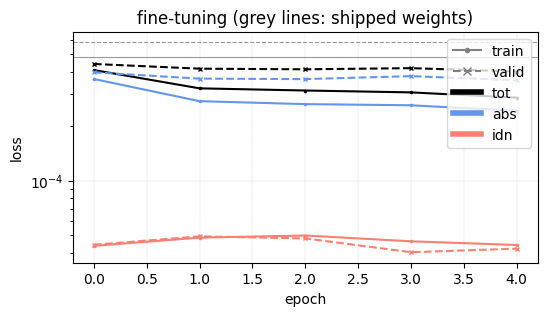

In [8]:
ax = L.plot({'train': train_loss, 'valid': valid_loss})
ax.axhline(baseline['train']['tot'][0], color='k', lw=0.8, ls='-',  alpha=0.4)
ax.axhline(baseline['valid']['tot'][0], color='k', lw=0.8, ls='--', alpha=0.4)
ax.set_title('fine-tuning (grey lines: shipped weights)')
plt.show()

## 5. Held-out test model (`data/test/mid_dens`)

- **step**: teacher-forced, every step starts from the true abundances (window length 1).
- **evolution**: fully autoregressive from `n[0]` over the whole model (one window of length N−1).

MSE in the normalised log-abundance space the model is trained in.

In [9]:
mod, (n, p, dt), _ = ds.get_test_data('1DCSE', 'mid_dens', meta, inpackage=True)
N = n.shape[0]

def predict(m, e):
    n0, p_seq, dt_seq, n_e = make_windows(n, p, dt, e)
    with torch.no_grad():
        n_e_hat, status = m.rollout(n0, p_seq, dt_seq)
    return n_e, n_e_hat, int((status != 0).sum())

results = {}
for label, m in [('original', original), ('fine-tuned', model)]:
    n_s, n_s_hat, f_s = predict(m, 1)
    n_v, n_v_hat, f_v = predict(m, N - 1)
    results[label] = n_v_hat[0]
    print(f'{label:10s} | step MSE {((n_s - n_s_hat)**2).mean():.3e} | '
          f'evolution MSE {((n_v - n_v_hat)**2).mean():.3e} | failed solves {f_s + f_v}')

> Train state: False
Found paths: 13
[12  5  0  3 11  3  7  9  3  5]
number of test paths: 3
Selected test paths: 3
Selected paths: 3


/System/Volumes/Data/STER/hydroModels/camille/phantom/macetraining/MACE/
-------------------
Input of test model
-------------------
Mdot [Msol/yr]:       1e-06
v [km/s]:             17.5
Density proxi Mdot/v: 5.714285714285714e-13

Temp at 1e16 cm [K]:  93.91
Tstar:                2100.0
eps:                  0.5
-------------------

original   | step MSE 2.703e-04 | evolution MSE 1.571e-03 | failed solves 0
fine-tuned | step MSE 2.462e-04 | evolution MSE 1.407e-03 | failed solves 0


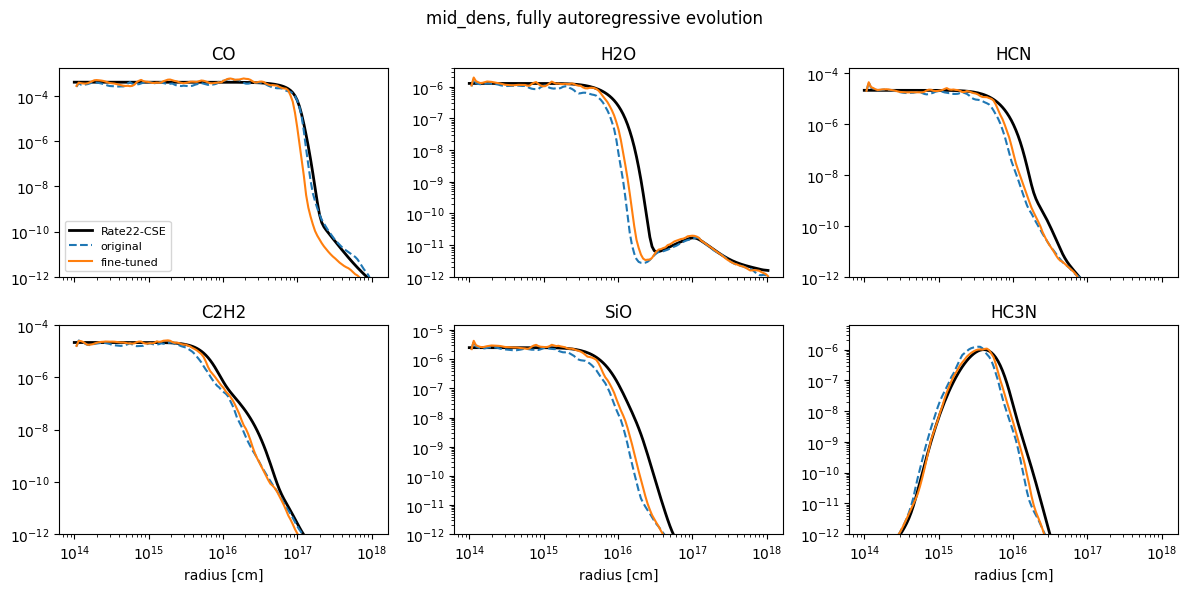

In [10]:
specs  = ['CO', 'H2O', 'HCN', 'C2H2', 'SiO', 'HC3N']
idx    = ds.specs_dict
radius = mod.radius

fig, axs = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, spec in zip(axs.flat, specs):
    i = idx[spec]
    ax.plot(radius, ds.get_abs(n[:, i].numpy()), 'k-', lw=2, label='Rate22-CSE')
    for (label, n_hat), style in zip(results.items(), ['--', '-']):
        ax.plot(radius[1:], ds.get_abs(n_hat[:, i].numpy()), style, label=label)
    ax.set(xscale='log', yscale='log', title=spec, ylim=(1e-12, None))
for ax in axs[-1]: ax.set_xlabel('radius [cm]')
axs[0, 0].legend(fontsize=8)
fig.suptitle('mid_dens, fully autoregressive evolution')
fig.tight_layout()
plt.show()

## 6. Save (optional)

In [11]:
if SAVE:
    out = Path('model') / f"{strftime('%Y%m%d_%H%M%S')}_finetune"
    (out / 'nn').mkdir(parents=True)
    torch.save(model.state_dict(), out / 'nn' / 'nn.pt')
    np.save(out / 'minmax.npy', np.load(WEIGHTS / 'minmax.npy'))
    train_loss.save(out / 'train')
    valid_loss.save(out / 'valid')
    json.dump(meta | {'finetuned_from': f'{WEIGHTS.name}/nn/nn{SNAPSHOT}.pt', 'finetune_epochs': NB_EPOCHS,
                      'finetune_lr': LR, 'model': out.name}, open(out / 'meta.json', 'w'), indent=4)
    print('saved to', out)